In [1]:
# This Python 3 environment comes with many helpful analytics libraries installed
# It is defined by the kaggle/python Docker image: https://github.com/kaggle/docker-python
# For example, here's several helpful packages to load

import numpy as np # linear algebra
import pandas as pd # data processing, CSV file I/O (e.g. pd.read_csv)

# Input data files are available in the read-only "../input/" directory
# For example, running this (by clicking run or pressing Shift+Enter) will list all files under the input directory

import os
for dirname, _, filenames in os.walk('/kaggle/input'):
    for filename in filenames:
        print(os.path.join(dirname, filename))

# You can write up to 20GB to the current directory (/kaggle/working/) that gets preserved as output when you create a version using "Save & Run All" 
# You can also write temporary files to /kaggle/temp/, but they won't be saved outside of the current session

# Use the kagglehub client library to attach Kaggle resources like competitions, datasets, and models to your session
# Learn more about kagglehub: https://github.com/Kaggle/kagglehub/blob/main/README.md

import kagglehub
# kagglehub.dataset_download('<owner>/<dataset-slug>')

/kaggle/input/datasets/batooljuaitem/titanic/gender_submission.csv
/kaggle/input/datasets/batooljuaitem/titanic/test.csv
/kaggle/input/datasets/batooljuaitem/titanic/train.csv


In [2]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    confusion_matrix
)

print("Libraries Imported Successfully!")

Libraries Imported Successfully!


In [3]:
df = pd.read_csv('/kaggle/input/datasets/batooljuaitem/titanic/train.csv')

print("Dataset Shape:", df.shape)

print("\nDataset Information:")
df.info()

print("\nFirst 5 Rows:")
display(df.head())

Dataset Shape: (891, 12)

Dataset Information:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 891 entries, 0 to 890
Data columns (total 12 columns):
 #   Column       Non-Null Count  Dtype  
---  ------       --------------  -----  
 0   PassengerId  891 non-null    int64  
 1   Survived     891 non-null    int64  
 2   Pclass       891 non-null    int64  
 3   Name         891 non-null    object 
 4   Sex          891 non-null    object 
 5   Age          714 non-null    float64
 6   SibSp        891 non-null    int64  
 7   Parch        891 non-null    int64  
 8   Ticket       891 non-null    object 
 9   Fare         891 non-null    float64
 10  Cabin        204 non-null    object 
 11  Embarked     889 non-null    object 
dtypes: float64(2), int64(5), object(5)
memory usage: 83.7+ KB

First 5 Rows:


,PassengerId,Survived,Pclass,Name,Sex,Age,SibSp,Parch,Ticket,Fare,Cabin,Embarked
0,1,0,3,"Braund, Mr. Owen Harris",male,22.0,1,0,A/5 21171,7.2500,NaN,S
1,2,1,1,"Cumings, Mrs. John Bradley (Florence Briggs Th...",female,38.0,1,0,PC 17599,71.2833,C85,C
2,3,1,3,"Heikkinen, Miss. Laina",female,26.0,0,0,STON/O2. 3101282,7.9250,NaN,S
3,4,1,1,"Futrelle, Mrs. Jacques Heath (Lily May Peel)",female,35.0,1,0,113803,53.1000,C123,S
4,5,0,3,"Allen, Mr. William Henry",male,35.0,0,0,373450,8.0500,NaN,S


In [4]:
df = df.drop(columns=['PassengerId', 'Name', 'Ticket', 'Cabin'])

print("Shape after dropping columns:", df.shape)
display(df.head())

Shape after dropping columns: (891, 8)


,Survived,Pclass,Sex,Age,SibSp,Parch,Fare,Embarked
0,0,3,male,22.0,1,0,7.2500,S
1,1,1,female,38.0,1,0,71.2833,C
2,1,3,female,26.0,0,0,7.9250,S
3,1,1,female,35.0,1,0,53.1000,S
4,0,3,male,35.0,0,0,8.0500,S


In [5]:
df['Age'] = df['Age'].fillna(df['Age'].median())
df['Embarked'] = df['Embarked'].fillna(df['Embarked'].mode()[0])

print("Missing Values After Treatment:")
print(df.isnull().sum())

Missing Values After Treatment:
Survived    0
Pclass      0
Sex         0
Age         0
SibSp       0
Parch       0
Fare        0
Embarked    0
dtype: int64


In [6]:
df['Sex'] = df['Sex'].map({'male': 0, 'female': 1})

df = pd.get_dummies(df, columns=['Embarked'], dtype=int)

print("Columns after Encoding:")
print(df.columns.tolist())

display(df.head())

Columns after Encoding:
['Survived', 'Pclass', 'Sex', 'Age', 'SibSp', 'Parch', 'Fare', 'Embarked_C', 'Embarked_Q', 'Embarked_S']


,Survived,Pclass,Sex,Age,SibSp,Parch,Fare,Embarked_C,Embarked_Q,Embarked_S
0,0,3,0,22.0,1,0,7.2500,0,0,1
1,1,1,1,38.0,1,0,71.2833,1,0,0
2,1,3,1,26.0,0,0,7.9250,0,0,1
3,1,1,1,35.0,1,0,53.1000,0,0,1
4,0,3,0,35.0,0,0,8.0500,0,0,1


In [7]:
X = df.drop('Survived', axis=1)
y = df['Survived']

print("X Shape:", X.shape)
print("y Shape:", y.shape)

X Shape: (891, 9)
y Shape: (891,)


In [8]:
X_train, X_test, y_train, y_test = train_test_split(
    X, y,
    test_size=0.2,
    random_state=42,
    stratify=y
)

print("X_train:", X_train.shape)
print("X_test:", X_test.shape)
print("y_train:", y_train.shape)
print("y_test:", y_test.shape)

X_train: (712, 9)
X_test: (179, 9)
y_train: (712,)
y_test: (179,)


In [9]:
scaler = StandardScaler()

X_train = scaler.fit_transform(X_train)
X_test = scaler.transform(X_test)

print("Standardization Completed!")
print("X_train Shape:", X_train.shape)
print("X_test Shape:", X_test.shape)

Standardization Completed!
X_train Shape: (712, 9)
X_test Shape: (179, 9)


In [10]:
def sigmoid(z):
    return 1 / (1 + np.exp(-z))

print("Sigmoid Function Defined!")

Sigmoid Function Defined!


In [11]:
def compute_loss(y_true, y_pred):
    epsilon = 1e-15
    y_pred = np.clip(y_pred, epsilon, 1 - epsilon)

    loss = -np.mean(
        y_true * np.log(y_pred) +
        (1 - y_true) * np.log(1 - y_pred)
    )

    return loss

print("Loss Function Defined!")

Loss Function Defined!


In [12]:
def train_rmsprop(X, y, learning_rate=0.01, epochs=1000, beta=0.9, epsilon=1e-8):

    m, n = X.shape

    weights = np.zeros(n)
    bias = 0

    s_w = np.zeros(n)
    s_b = 0

    loss_history = []

    for epoch in range(epochs):

        y_pred = sigmoid(np.dot(X, weights) + bias)

        dw = np.dot(X.T, (y_pred - y)) / m
        db = np.mean(y_pred - y)

        s_w = beta * s_w + (1 - beta) * (dw ** 2)
        s_b = beta * s_b + (1 - beta) * (db ** 2)

        weights -= learning_rate * dw / (np.sqrt(s_w) + epsilon)
        bias -= learning_rate * db / (np.sqrt(s_b) + epsilon)

        predictions = sigmoid(np.dot(X, weights) + bias)
        loss = compute_loss(y, predictions)

        loss_history.append(loss)

    return weights, bias, loss_history

print("RMSProp Algorithm Defined!")

RMSProp Algorithm Defined!


In [13]:
weights_rmsprop, bias_rmsprop, loss_history_rmsprop = train_rmsprop(
    X_train,
    y_train,
    learning_rate=0.01,
    epochs=1000,
    beta=0.9
)

print("RMSProp Training Completed!")

RMSProp Training Completed!


In [14]:
for i in range(0, len(loss_history_rmsprop), 100):
    print(f"Epoch {i+1}, Loss: {loss_history_rmsprop[i]:.4f}")

Epoch 1, Loss: 0.6645
Epoch 101, Loss: 0.4435
Epoch 201, Loss: 0.4363
Epoch 301, Loss: 0.4363
Epoch 401, Loss: 0.4363
Epoch 501, Loss: 0.4363
Epoch 601, Loss: 0.4363
Epoch 701, Loss: 0.4363
Epoch 801, Loss: 0.4363
Epoch 901, Loss: 0.4363


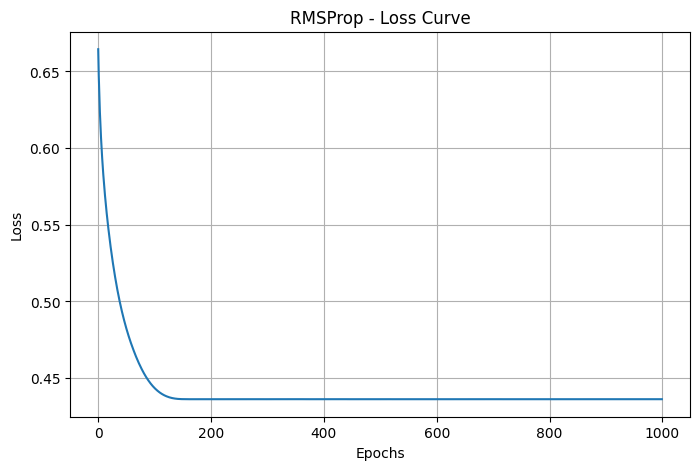

In [15]:
plt.figure(figsize=(8, 5))
plt.plot(loss_history_rmsprop)

plt.title("RMSProp - Loss Curve")
plt.xlabel("Epochs")
plt.ylabel("Loss")
plt.grid(True)

plt.show()

In [16]:
y_prob_rmsprop = sigmoid(np.dot(X_test, weights_rmsprop) + bias_rmsprop)

y_pred_rmsprop = (y_prob_rmsprop >= 0.5).astype(int)

print("Predictions:", y_pred_rmsprop[:10])

Predictions: [0 0 0 0 1 0 1 0 0 0]


In [17]:
accuracy = accuracy_score(y_test, y_pred_rmsprop)
precision = precision_score(y_test, y_pred_rmsprop)
recall = recall_score(y_test, y_pred_rmsprop)
f1 = f1_score(y_test, y_pred_rmsprop)

print("RMSProp Results:")
print("Accuracy:", accuracy)
print("Precision:", precision)
print("Recall:", recall)
print("F1 Score:", f1)

RMSProp Results:
Accuracy: 0.8044692737430168
Precision: 0.7931034482758621
Recall: 0.6666666666666666
F1 Score: 0.7244094488188977


In [18]:
cm_rmsprop = confusion_matrix(y_test, y_pred_rmsprop)

print("RMSProp Confusion Matrix:")
print(cm_rmsprop)

RMSProp Confusion Matrix:
[[98 12]
 [23 46]]


In [19]:
def train_rmsprop_momentum(
    X, y,
    learning_rate=0.01,
    epochs=1000,
    beta=0.9,
    momentum=0.9,
    epsilon=1e-8
):

    m, n = X.shape

    weights = np.zeros(n)
    bias = 0

    s_w = np.zeros(n)
    s_b = 0

    v_w = np.zeros(n)
    v_b = 0

    loss_history = []

    for epoch in range(epochs):

        y_pred = sigmoid(np.dot(X, weights) + bias)

        dw = np.dot(X.T, (y_pred - y)) / m
        db = np.mean(y_pred - y)

        s_w = beta * s_w + (1 - beta) * (dw ** 2)
        s_b = beta * s_b + (1 - beta) * (db ** 2)

        adjusted_dw = dw / (np.sqrt(s_w) + epsilon)
        adjusted_db = db / (np.sqrt(s_b) + epsilon)

        v_w = momentum * v_w + learning_rate * adjusted_dw
        v_b = momentum * v_b + learning_rate * adjusted_db

        weights -= v_w
        bias -= v_b

        predictions = sigmoid(np.dot(X, weights) + bias)
        loss = compute_loss(y, predictions)

        loss_history.append(loss)

    return weights, bias, loss_history

print("RMSProp with Momentum Algorithm Defined!")

RMSProp with Momentum Algorithm Defined!


In [20]:
weights_rmsprop_momentum, bias_rmsprop_momentum, loss_history_rmsprop_momentum = train_rmsprop_momentum(
    X_train,
    y_train,
    learning_rate=0.01,
    epochs=1000,
    beta=0.9,
    momentum=0.9
)

print("RMSProp with Momentum Training Completed!")

RMSProp with Momentum Training Completed!


In [21]:
for i in range(0, len(loss_history_rmsprop_momentum), 100):
    print(f"Epoch {i+1}, Loss: {loss_history_rmsprop_momentum[i]:.4f}")

Epoch 1, Loss: 0.6645
Epoch 101, Loss: 0.4363
Epoch 201, Loss: 0.4363
Epoch 301, Loss: 0.4363
Epoch 401, Loss: 0.4363
Epoch 501, Loss: 0.4363
Epoch 601, Loss: 0.4363
Epoch 701, Loss: 0.4363
Epoch 801, Loss: 0.4363
Epoch 901, Loss: 0.4363


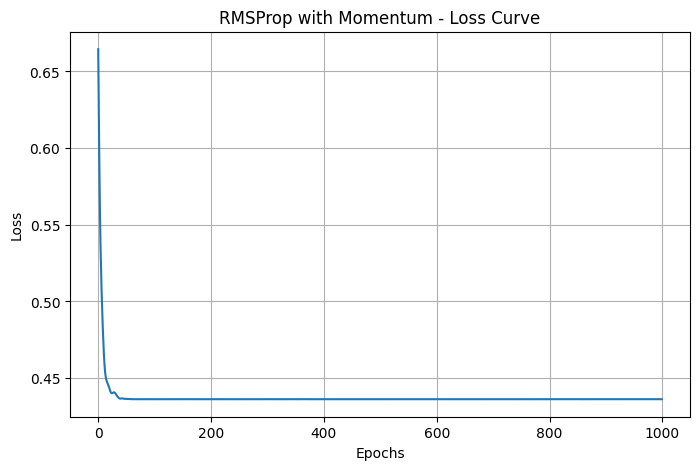

In [22]:
plt.figure(figsize=(8, 5))
plt.plot(loss_history_rmsprop_momentum)

plt.title("RMSProp with Momentum - Loss Curve")
plt.xlabel("Epochs")
plt.ylabel("Loss")
plt.grid(True)

plt.show()

In [23]:
y_prob_rmsprop_momentum = sigmoid(
    np.dot(X_test, weights_rmsprop_momentum) + bias_rmsprop_momentum
)

y_pred_rmsprop_momentum = (
    y_prob_rmsprop_momentum >= 0.5
).astype(int)

print("Predictions:", y_pred_rmsprop_momentum[:10])

Predictions: [0 0 0 0 1 0 1 0 0 0]


In [24]:
accuracy = accuracy_score(y_test, y_pred_rmsprop_momentum)
precision = precision_score(y_test, y_pred_rmsprop_momentum)
recall = recall_score(y_test, y_pred_rmsprop_momentum)
f1 = f1_score(y_test, y_pred_rmsprop_momentum)

print("RMSProp with Momentum Results:")
print("Accuracy:", accuracy)
print("Precision:", precision)
print("Recall:", recall)
print("F1 Score:", f1)

RMSProp with Momentum Results:
Accuracy: 0.8044692737430168
Precision: 0.7931034482758621
Recall: 0.6666666666666666
F1 Score: 0.7244094488188977


In [25]:
cm_rmsprop_momentum = confusion_matrix(
    y_test,
    y_pred_rmsprop_momentum
)

print("RMSProp with Momentum Confusion Matrix:")
print(cm_rmsprop_momentum)

RMSProp with Momentum Confusion Matrix:
[[98 12]
 [23 46]]


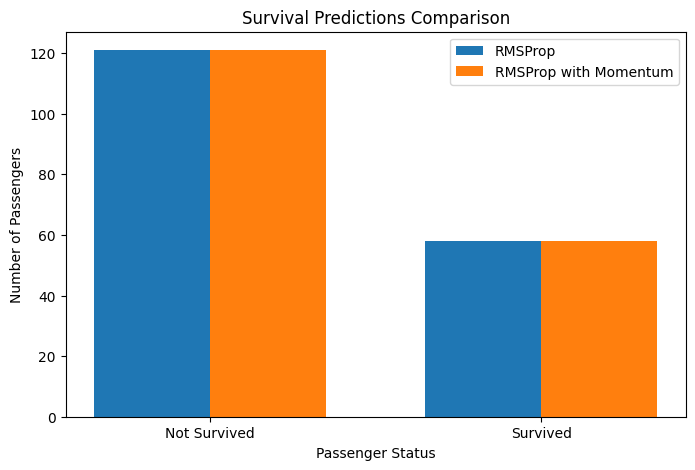

In [26]:
rmsprop_not_survived = np.sum(y_pred_rmsprop == 0)
rmsprop_survived = np.sum(y_pred_rmsprop == 1)

momentum_not_survived = np.sum(y_pred_rmsprop_momentum == 0)
momentum_survived = np.sum(y_pred_rmsprop_momentum == 1)

labels = ['Not Survived', 'Survived']

rmsprop_counts = [rmsprop_not_survived, rmsprop_survived]
momentum_counts = [momentum_not_survived, momentum_survived]

x = np.arange(len(labels))
width = 0.35

plt.figure(figsize=(8, 5))

plt.bar(x - width/2, rmsprop_counts, width, label='RMSProp')
plt.bar(x + width/2, momentum_counts, width, label='RMSProp with Momentum')

plt.xlabel('Passenger Status')
plt.ylabel('Number of Passengers')
plt.title('Survival Predictions Comparison')

plt.xticks(x, labels)
plt.legend()
plt.show()

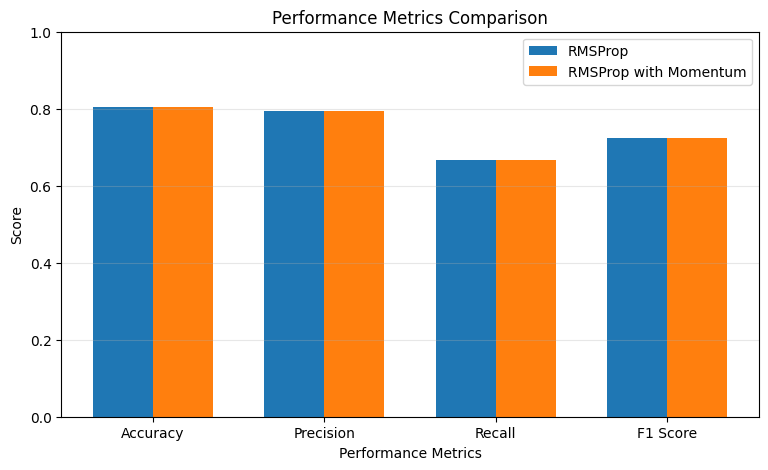

In [27]:
metrics = ['Accuracy', 'Precision', 'Recall', 'F1 Score']

rmsprop_scores = [
    accuracy_score(y_test, y_pred_rmsprop),
    precision_score(y_test, y_pred_rmsprop),
    recall_score(y_test, y_pred_rmsprop),
    f1_score(y_test, y_pred_rmsprop)
]

momentum_scores = [
    accuracy_score(y_test, y_pred_rmsprop_momentum),
    precision_score(y_test, y_pred_rmsprop_momentum),
    recall_score(y_test, y_pred_rmsprop_momentum),
    f1_score(y_test, y_pred_rmsprop_momentum)
]

x = np.arange(len(metrics))
width = 0.35

plt.figure(figsize=(9, 5))

plt.bar(x - width/2, rmsprop_scores, width, label='RMSProp')
plt.bar(x + width/2, momentum_scores, width, label='RMSProp with Momentum')

plt.xlabel('Performance Metrics')
plt.ylabel('Score')
plt.title('Performance Metrics Comparison')

plt.xticks(x, metrics)
plt.ylim(0, 1)
plt.legend()
plt.grid(axis='y', alpha=0.3)

plt.show()

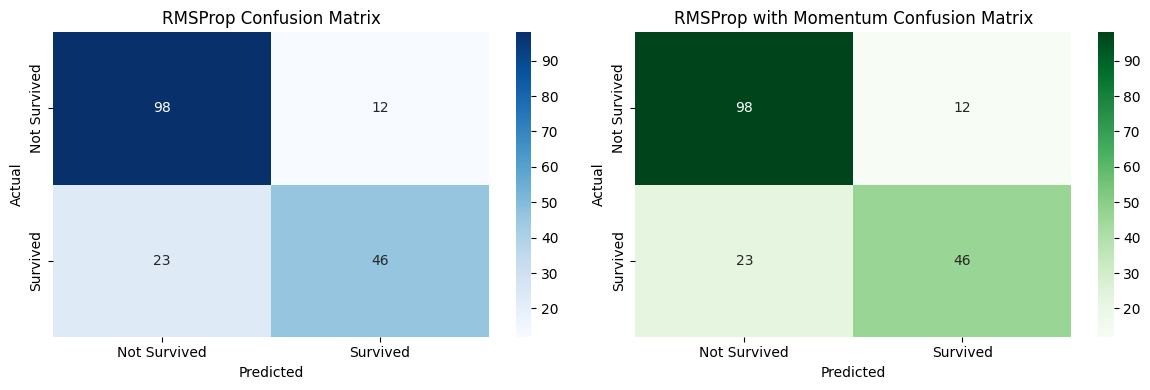

In [28]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4))

sns.heatmap(
    cm_rmsprop,
    annot=True,
    fmt='d',
    cmap='Blues',
    xticklabels=['Not Survived', 'Survived'],
    yticklabels=['Not Survived', 'Survived'],
    ax=axes[0]
)

axes[0].set_title("RMSProp Confusion Matrix")
axes[0].set_xlabel("Predicted")
axes[0].set_ylabel("Actual")

sns.heatmap(
    cm_rmsprop_momentum,
    annot=True,
    fmt='d',
    cmap='Greens',
    xticklabels=['Not Survived', 'Survived'],
    yticklabels=['Not Survived', 'Survived'],
    ax=axes[1]
)

axes[1].set_title("RMSProp with Momentum Confusion Matrix")
axes[1].set_xlabel("Predicted")
axes[1].set_ylabel("Actual")

plt.tight_layout()
plt.show()

In [29]:
print("Identical Predictions:",
      np.array_equal(y_pred_rmsprop, y_pred_rmsprop_momentum))

print("Different Predictions:",
      np.sum(y_pred_rmsprop != y_pred_rmsprop_momentum))

Identical Predictions: True
Different Predictions: 0


In [30]:
print("RMSProp Final Loss:", loss_history_rmsprop[-1])
print("RMSProp Momentum Final Loss:", loss_history_rmsprop_momentum[-1])

print("Maximum Probability Difference:",
      np.max(np.abs(y_prob_rmsprop - y_prob_rmsprop_momentum)))

RMSProp Final Loss: 0.4363028815476727
RMSProp Momentum Final Loss: 0.4362894346267555
Maximum Probability Difference: 0.027185622993145087
